# Algorithms Challenge: Journey to mastery
## Model 01: Linear Regression (End-to-End car resale prediction)

**Author:**  Tyra Nyambura

**Date:** 18th Oct, 2026

**Goal:** Mastering 68 Machine Learning algorithms blending deep mathematical theory with real-world, hands-on implementations

### Welcome to my journey
This notebook marks the official start of my quest to break down and implement 68 different machine learning models. I've spent time diving deep into the linear algebra, calculus and matrix optimizations behind **Linear Regression**. Now, it's time to put that theory into practice.

### Today's mission:
We are going to build a predictive model from scratch using the **Car-Dekho Dataset from Kaggle**. Our goal is to predict a car's resale value based on features like age, mileage, fuel type, and dealer type.

### Why Linear Regression?
Linear Regression assumes a linear relationship between input features and continuous target output. Mathematically, we are trying to map our data to the equation:

$$y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \dots + \beta_nX_n + \epsilon$$

Where:
* $y$ is our target (**Selling Price**)
* $\beta_0$ is the intercept
* $\beta_1, \beta_2...$ are the learned weights/coefficients for each car feature
* $\epsilon$ is the residual error

Let's begin our workflow!

### Step 1: Loading our Toolkit
Before messing with the data, we need to load the core Python libraries. We'll use `Pandas` and `numpy` for handling arrays and matrices, `matplotlib` and `seaborn` to visualize our errors, and `scikit-learn` to handle data splitting, modeling, and mathematical metrics.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

print("Toolkit loaded and ready for analysis!")

Toolkit loaded and ready for analysis!


### Step 2: Data loading & first impressions
A good engineer never feeds raw data straight into a model blindfolded. We need to load our raw CSV file downloaded from Kaggle, inspect its layout, check its shape, and verify if we have to deal with missing data (null values)

In [2]:
df = pd.read_csv('../../data/vehicle-dataset/CAR DETAILS FROM CAR DEKHO.csv')

print(f"Data shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
print("Features and data types")
print(df.dtypes)
print("\n Missing values counter")
print(df.isnull().sum())

# Look at the first 5 records
df.head()

Data shape: 4340 rows, 8 columns

Features and data types
name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object

 Missing values counter
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


### Step 3: Feature engineering (The logic of "Car Age")
Now that our 4,340 records are cleanly loaded, we face our first real design choice. The dataset contains a columns called `year` (e.g., 2014, 2018).

If we feed raw years directly into a Linear Regression model, the mathematical equation treats them as absolute timeline scale. But a car's value doesn't change because of the calendar year number itself-it changes due to **deprecation over time**.

To fix this, we will engineer a new, intuitive linear feature called **`Car Age`**.


#### The formula:
{Car_Age} = {Current_Year (2026)} - {Year}

#### Why this helps our model's math:
1. **Direct deprecation tracking:** A 1-year-old car maintains high value, whereas a 12 year old car drops significantly. This inverse linear relationship is much cleaner for calculating the model's weight coefficient (β).

2. **Dropping irrelevant text:** We will also drop the `name` column here. With 4,000+ records, individual model names create too many unique strings (high cardinality) which will break a simple linear model. We want our model to look at the **metrics** of the car instead of its brand name text.


Let's execute this transformation.

In [3]:
# Calculate the actual age of the car relative to the current year (2026)
df['car_age'] = 2026 - df['year']

# Drop 'year' since it's redundant, and the 'name' due to high text variance
df_engineered = df.drop(columns=['year', 'name'])

# Check the first 5 records to verify our new feature structure
df_engineered.head()

,selling_price,km_driven,fuel,seller_type,transmission,owner,car_age
0,60000,70000,Petrol,Individual,Manual,First Owner,19
1,135000,50000,Petrol,Individual,Manual,First Owner,19
2,600000,100000,Diesel,Individual,Manual,First Owner,14
3,250000,46000,Petrol,Individual,Manual,First Owner,9
4,450000,141000,Diesel,Individual,Manual,Second Owner,12


### Step 4: Converting text to numbers (Categorical encoding)

Linear Regression is entirely built on matrix algebra (\(Y = X\beta + \epsilon\)). Because of this, it cannot natively read categorical strings like `"Diesel"`, `"Individual"`, or `"Manual"`. We must map these into discrete numerical representations.

To achieve this cleanly, we use a technique called **One-Hot Encoding**.

#### How One-Hot Encoding works:
For a column like `transmission` which has two unique values (`Manual` and `Automatic`). One-Hot Encoding creates a new binary column. If a car is manual, it gets a `1`; if it's automatic, it gets a `0`.


#### Avoiding the dummy variable trap (Multicollinearity):
If a categorical column has 3 options (like `fuel`: *Petrol*, *Diesel*, *CNG*), we only need **2** binary columns to represent all choices:

* If `fuel_diesel = 0` and `fuel_petrol = 0`, the math instantly deduces the car is *CNG*.

Including that 3rd column creates perfect multicollinearity-where features predict each other. This breaks the ordinary least squares (OLS) matrix inversion process (\(X^TX)^{-1}\). To prevent this, we set `drop_first=True`.


Let's convert our categorical columns (`fuel`, `seller_type`, `transmission`, and `owner`) into numeric flags.

In [4]:
# Convert categorical features into numerical binary dummy columns
# drop_first=True eliminates one redundant column per category to protect our regression math
df_encoded = pd.get_dummies(
    df_engineered,
    columns=['fuel', 'seller_type', 'transmission', 'owner'],
    drop_first=True
)

df_encoded = df_encoded.astype(int)

# Inspect our newly expanded numerical feature matrix
print(f"New encoded dataset shape: {df_encoded.shape[0]} rows, {df_encoded.shape[1]} columns")
df_encoded.head()

New encoded dataset shape: 4340 rows, 14 columns


,selling_price,km_driven,car_age,fuel_Diesel,fuel_Electric,fuel_LPG,fuel_Petrol,seller_type_Individual,seller_type_Trustmark Dealer,transmission_Manual,owner_Fourth & Above Owner,owner_Second Owner,owner_Test Drive Car,owner_Third Owner
0,60000,70000,19,0,0,0,1,1,0,1,0,0,0,0
1,135000,50000,19,0,0,0,1,1,0,1,0,0,0,0
2,600000,100000,14,1,0,0,0,1,0,1,0,0,0,0
3,250000,46000,9,0,0,0,1,1,0,1,0,0,0,0
4,450000,141000,12,1,0,0,0,1,0,1,0,1,0,0


### Step 5: Splitting data into train and test sets
Now that our feature matrix is completely numerical, it is time to prepare our data for training. However, we cannot train our model on the entire dataset. If we use 100% of our data to train the linear model, we will have no way of knowing whether the model actually learned the underlying patterns or if it simply memorized the dataset.

In Machine Learning, our ultimate goal is **generalization** - the ability of our linear equation to make highly accurate predictions on completely unseen, real-world cars.

#### Splitting the data into two camps:
1. **Training set (80%):** The historical data our Linear Regression model will look at to optimize its weight and intercept (\(\beta\) values).
2. **Testing set (20%):** The hidden evaluation data. The model never sees these rows during training. We use them as a "final exam" to judge its true predictive power.

#### Isolating the target:
We will separate our independent predictors (\(X\)) from our dependent target variable (\(y\)), which is `selling_price`.

Let's execute the split using `train_test_split`, we'll use a `random_state` so that our data shuffling remains exactly reproducible every time we run this notebook.

In [5]:
# Separate the independent variables (X) from our target variable (y)
y = df_encoded['selling_price']
X = df_encoded.drop(columns=['selling_price'])

# Partition the data into an 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print out the matrix dimensions to verify our split worked correctly
print("Matrix Dimensions")
print(f"Training Features (X_train): {X_train.shape[0]} rows, {X_train.shape[1]} columns")
print(f"Training Target   (y_train): {y_train.shape[0]} rows")
print(f"Testing Features  (X_test):  {X_test.shape[0]} rows, {X_test.shape[1]} columns")
print(f"Testing Target    (y_test):  {y_test.shape[0]} rows")

--- Matrix Dimensions ---
Training Features (X_train): 3472 rows, 13 columns
Training Target   (y_train): 3472 rows
Testing Features  (X_test):  868 rows, 13 columns
Testing Target    (y_test):  868 rows


### Step 6: Initializing and Training the Model

This is the exact moment where mathematical preparation meets the data. We are initializing the `LinearRegression()` engine from `scikit-learn` and feeding our training data into it using the `.fit()` method.

#### What happens behind the scenes?
When we run `model.fit(X_train, y_train)`, the computer doesn't guess numbers randomly. It solves a precise, closed-form linear algebra equation known as the **Normal Equation**:

\[\mathbf{\beta} = (\mathbf{X}^T\mathbf{X})^{-1}\mathbf{X}^T\mathbf{y}\]

Here is exactly what the algorithm is calculating internally:
1. **\(\mathbf{X}^T\mathbf{X}\)**: It takes our feature matrix, transposes it, and multiplies it by itself to create a square matrix that maps all feature interactions.
2. **\((\dots)^{-1}\)**: It calculates the matrix inverse. This is the equivalent of dividing, allowing the algorithm to solve for the unknown weights.
3. **Ordinary Least Squares (OLS):** The ultimate goal of this matrix operation is to minimize the **Residual Sum of Squares (RSS)** - which is the squared distance between the actual prices and the prices predicted by our linear plane.



In [6]:
# Initialize our linear regression model engine
lr_model = LinearRegression()

# Run the matrix algebra optimization on our training subset
lr_model.fit(X_train, y_train)

print("Linear Regression model training complete! The optimal weights have been calculated.")


Linear Regression model training complete! The optimal weights have been calculated.


### Step 7: Model Evaluation Metrics

Our model has successfully calculated its optimal coefficients. Now, we must put it to the test using our hidden `X_test` data to generate predictions. To evaluate how close our model's predictions are to the true actual selling prices (`y_test`), we use three standard regression metrics. 

Here is what they mean mathematically:

#### 1. Mean Absolute Error (MAE)
MAE measures the average magnitude of the errors in a set of predictions, without considering their direction. It is the average absolute vertical distance between each data point and our regression line:
\[\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} \vert{}y_i - \hat{y}_i\vert{}\]
* **In plain terms:** On average, how many Rupees off is our prediction from the true price?

#### 2. Root Mean Squared Error (RMSE)
RMSE squares the errors before averaging them, and then takes the square root. Because it squares the errors, it severely punishes larger, catastrophic miscalculations:
\[\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2}\]
* **In plain terms:** If our model makes a few massive pricing blunders, RMSE will skyrocket compared to MAE. It keeps us honest about major outliers.

#### 3. Coefficient of Determination (\(R^2\) Score)
The \(R^2\) score represents the proportion of variance in the dependent variable that is predictable from our independent variables:
\[R^2 = 1 - \frac{\text{SS}_{\text{res}}}{\text{SS}_{\text{tot}}}\]
* **In plain terms:** A score of `1.0` means a perfect model. A score of `0.60` means our features (mileage, age, fuel type) successfully explain 60% of the variance in car prices, leaving the other 40% down to random noise or factors we haven't tracked.


In [7]:
# Pass the unseen test features through our optimized linear equation to get predictions
predictions = lr_model.predict(X_test)

# Calculate the mathematical evaluation scores
mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

# Display the performance results
print("Model Performance Metrics")
print(f"Mean Absolute Error (MAE):       {mae:,.2f} Rupees")
print(f"Root Mean Squared Error (RMSE):  {rmse:,.2f} Rupees")
print(f"R-squared (R²) Score:            {r2:.4f}")


Model Performance Metrics
Mean Absolute Error (MAE):       221,706.37 Rupees
Root Mean Squared Error (RMSE):  426,786.69 Rupees
R-squared (R²) Score:            0.4031


### Step 8: Visualizing the Residuals & Predictions

The final step in this end-to-end journey is to convert our raw metric numbers into a visual story. While an \(R^2\) score tells us the strength of our linear equation, a **Scatter Plot of Actual vs. Predicted Prices** exposes *where* the model succeeds and *where* it breaks down.

#### How to read this visualization:
* **The Perfect Line (Red Dashed Line):** We will overlay a diagonal line representing \(y = x\). If our model was 100% accurate, every single data point would sit perfectly on this line (Actual Price = Predicted Price).
* **The Spread (Blue Clusters):** Points clustering tightly around the dashed line indicate high precision. Points wandering far away reveal cars that our model significantly overvalued or undervalued. 
* **Spotting Nonlinearity:** If the dots curve away from our straight line at higher prices, it visually proves that the true relationship isn't purely linear—giving us a perfect talking point for why we might need to explore advanced models later in our 68-algorithm challenge!

Let's use `matplotlib` and `seaborn` to generate this graph.


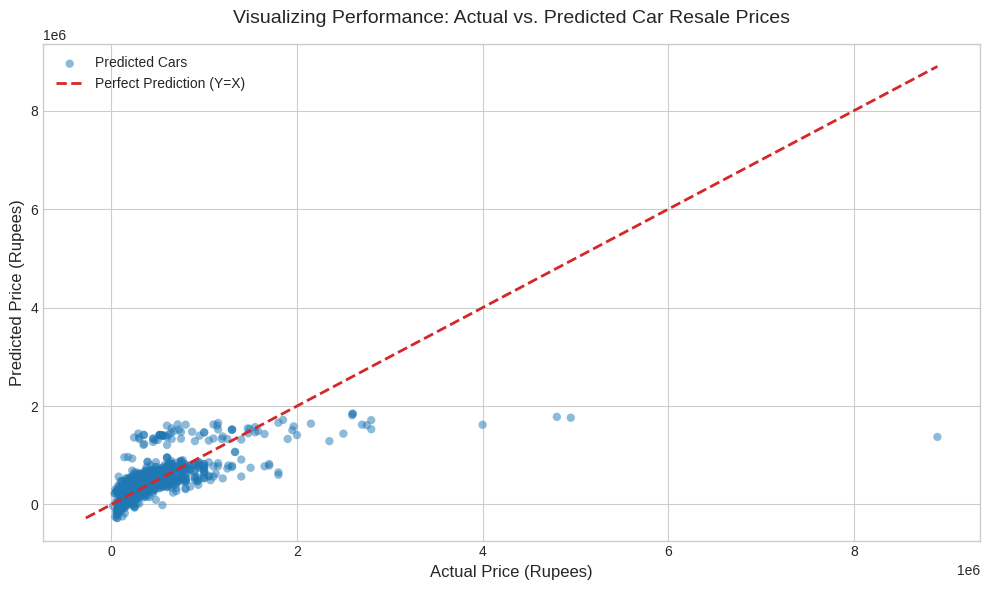

In [8]:
# Set up a clean, high-resolution plotting canvas
plt.figure(figsize=(10, 6), dpi=100)

# Plot actual vs predicted values as a scatter plot
plt.scatter(y_test, predictions, alpha=0.5, color='#1f77b4', edgecolor='none', label='Predicted Cars')

# Calculate the absolute min and max bounds across both axes to draw a perfect 45-degree line
min_val = min(y_test.min(), predictions.min())
max_val = max(y_test.max(), predictions.max())

# Draw the identity reference line (Perfect Predictions)
plt.plot([min_val, max_val], [min_val, max_val], color='#d62728', linestyle='--', linewidth=2, label='Perfect Prediction (Y=X)')

# Label the plot elements accurately with formatting
plt.title('Visualizing Performance: Actual vs. Predicted Car Resale Prices', fontsize=14, pad=15)
plt.xlabel('Actual Price (Rupees)', fontsize=12)
plt.ylabel('Predicted Price (Rupees)', fontsize=12)
plt.legend(loc='upper left', fontsize=10)

# Clean up layout structure and render the plot
plt.tight_layout()
plt.show()